# FallAllD basic fall model for Arduino

## Overview
This notebook contains model for fall detection intended for an Arduino using FallAllD. "FallAllD  is a large open dataset of human falls and activities of daily living simulated by 15 participants. FallAllD consists of 26420 files collected using three data-loggers worn on the waist, wrist and neck of the subjects. Motion signals are captured using an accelerometer, gyroscope, magnetometer and barometer". 

For the intented of this model only **the waist accelerometer data** was used as it is the location and type of data colected from the Arduino.

* **Dataset:** FallAllD subset (Waist accelerometer sensor streams filtered from trials across 15 participants)  
* **Target variable:** `Target` (0 = Safe / Activity of Daily Living, 1 = Fall)  
* **Goal:** Train a lightweight, accelerometer-based classification model to distinguish between regular daily movements and dangerous falls, optimized for real-time inference on an Arduino.

In [2]:
%load_ext autoreload
%autoreload 2

In [2]:
%run ../data/raw/FallAllD_2_PYTHON_Structure.py

File  1  out of 6605
File  2  out of 6605
File  3  out of 6605
File  4  out of 6605
File  5  out of 6605
File  6  out of 6605
File  7  out of 6605
File  8  out of 6605
File  9  out of 6605
File  10  out of 6605
File  11  out of 6605
File  12  out of 6605
File  13  out of 6605
File  14  out of 6605
File  15  out of 6605
File  16  out of 6605
File  17  out of 6605
File  18  out of 6605
File  19  out of 6605
File  20  out of 6605
File  21  out of 6605
File  22  out of 6605
File  23  out of 6605
File  24  out of 6605
File  25  out of 6605
File  26  out of 6605
File  27  out of 6605
File  28  out of 6605
File  29  out of 6605
File  30  out of 6605
File  31  out of 6605
File  32  out of 6605
File  33  out of 6605
File  34  out of 6605
File  35  out of 6605
File  36  out of 6605
File  37  out of 6605
File  38  out of 6605
File  39  out of 6605
File  40  out of 6605
File  41  out of 6605
File  42  out of 6605
File  43  out of 6605
File  44  out of 6605
File  45  out of 6605
File  46  out of 66

C:\Users\ruben\Fall-detection\data\raw\FallAllD_2_PYTHON_Structure.py:68: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block1_values] [items->Index(['Acc', 'Gyr', 'Mag', 'Bar'], dtype='str')]

  FallAllD.to_hdf(processed_FP + 'FallAllD.h5', key='df', mode='w')


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
import sys
sys.path.append("../src")
from fall_detection.windowing import extract_windows, fs
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from fall_detection.features_selection import feature_selection
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
from fall_detection.activity import ACTIVITY_NAMES

FallAllD = pd.read_pickle('../data/processed/FallAllD.pkl')


## 1. Data Exploration
Initial inspection of the dataset.

In [4]:
print(FallAllD.head())
print(FallAllD.columns.tolist())
print(FallAllD['Device'].unique())
print("Unique ActivityIDs:", FallAllD['ActivityID'].unique())

   SubjectID Device  ActivityID  TrialNo  \
0          1   Neck          13        1   
1          1   Neck          13        2   
2          1   Neck          13        3   
3          1   Neck          13        4   
4          1   Neck          13        5   

                                                 Acc  \
0  [[4155, 55, -82], [4157, 55, -126], [4157, 50,...   
1  [[4002, -50, 156], [4002, -38, 172], [4003, -2...   
2  [[3983, 40, -335], [3984, 38, -324], [3987, 34...   
3  [[3959, 165, 197], [3953, 165, 196], [3951, 16...   
4  [[3750, -182, 252], [3767, -166, 259], [3781, ...   

                                                 Gyr  \
0  [[1613, 205, 77], [1626, 202, 74], [1634, 199,...   
1  [[-57, 58, 18], [-64, 57, 15], [-66, 51, 16], ...   
2  [[1651, 208, 63], [1652, 203, 60], [1656, 198,...   
3  [[-70, 73, 2], [-67, 80, 4], [-70, 89, 5], [-7...   
4  [[394, -59, 3], [397, -63, -1], [394, -66, -3]...   

                                                 Mag  \
0  [[

## 2. Add New Columns

Created two new columns to prepare the dataset for modeling:
* **`Target`**: A binary label derived from the `ActivityID` (`0` for Safe / ADLs, and `1` for Falls where ID > 100).
* **`Acc_g`**: Converts the raw 16-bit signed integer accelerometer counts into standard gravitational units (**g**).

In [5]:
FallAllD['Target'] = FallAllD['ActivityID'].apply(lambda ActId: 1 if ActId > 100 else 0)
FallAllD['Acc_g'] = FallAllD['Acc'].apply(lambda raw: (raw / 32767.0) * 8.0)

## 3. Filter for Waist Data and Extract Features

Since our physical Arduino setup is probaly going to be worn on the waist, I filter the dataset to keep only the trials recorded from the `'Waist'` device. Then, I separate our accelerometer feature data (`x_acceleration`) from our binary classification targets (`y_target`).

In [6]:
x_bp = FallAllD[FallAllD['Device'] == 'Waist']

x_acceleration = x_bp['Acc_g']

y_target = x_bp['Target']


## 4. Inspect Class Balance and Data Shape

Before training a model, it is important to check two things:
1. **Class Balance (`value_counts`):** To check the distribution between fall samples and daily activities. While a severe class imbalance might require special handling, the ratio here (466 falls vs. 1,332 ADLs) is quite manageable.
2. **Data Shape (`np.shape`):** To confirm the dimensions of our accelerometer arrays (4,760 samples, which corresponds to a 20-second recording at a 238 Hz sampling rate).

To inspect what these recordings actually look like, I extract a single representative trial for both a **Fall** (`fall`) and an **Activity of Daily Living** (`adl`) using `.iloc[0]`. This allows us to visualize their waveform characteristics.

In [7]:
print(y_target.value_counts())

fall = x_acceleration[y_target == 1].iloc[0]
adl  = x_acceleration[y_target == 0].iloc[0]

print(type(fall), np.shape(fall))


Target
0    1332
1     466
Name: count, dtype: int64
<class 'numpy.ndarray'> (4760, 3)


## 5. Signal Visualization & Downsampling (238 Hz vs. 50 Hz)

To understand how our data looks and how downsampling affects it, I plot the vector magnitude ($\sqrt{x^2 + y^2 + z^2}$) of our acceleration data. 

I look at three views:
1. **Original Frequency (238 Hz):** Comparing Fall vs. ADL at full resolution.
2. **Downsampled Frequency (50 Hz):** Simulating a lower sampling rate (using `resample_poly`), which is common in embedded systems to save CPU cycles.
3. **Side-by-Side Comparison:** Time-aligned plots comparing the original frequency against the 50 Hz version for both activities.

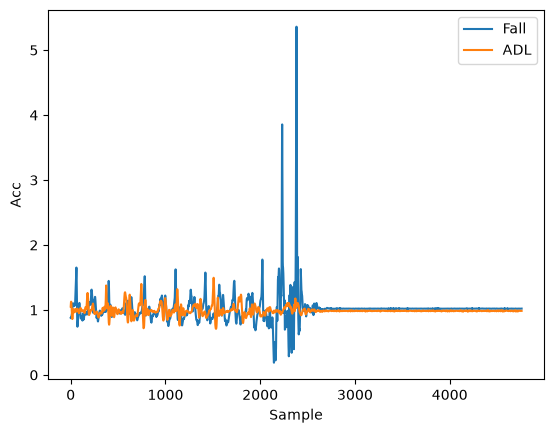

In [8]:
for sig, label in [(fall, "Fall"), (adl, "ADL")]:
    sig = np.asarray(sig)           
    plt.plot(np.linalg.norm(sig, axis=1), label=label)


plt.legend(); plt.xlabel("Sample"); plt.ylabel("Acc"); plt.show()

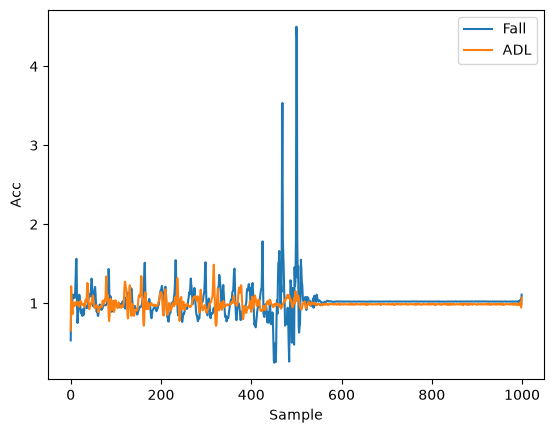

In [9]:
fs_in, fs_out = 238, 50

for sig, label in [(fall, "Fall"), (adl, "ADL")]:
    sig_ds = resample_poly(sig, up=25, down=119, axis=0)          
    plt.plot(np.linalg.norm(sig_ds, axis=1), label=label)

plt.legend(); plt.xlabel("Sample"); plt.ylabel("Acc"); plt.show()


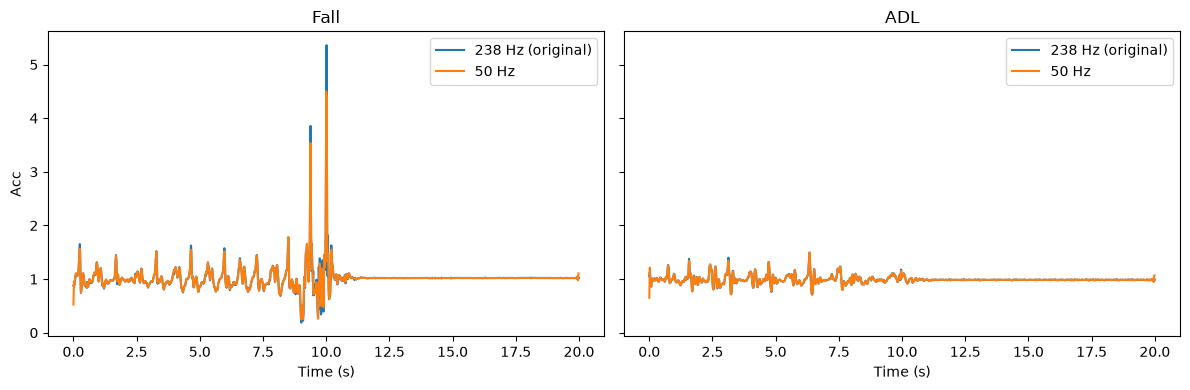

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (sig, label) in zip(axes, [(fall, "Fall"), (adl, "ADL")]):
    sig = np.asarray(sig) 
    sig_ds = resample_poly(sig, up=25, down=119, axis=0) 

    t_in = np.arange(len(sig)) / fs_in
    t_ds = np.arange(len(sig_ds)) / fs_out

    ax.plot(t_in, np.linalg.norm(sig, axis=1), label="238 Hz (original)")
    ax.plot(t_ds, np.linalg.norm(sig_ds, axis=1), label="50 Hz")
    ax.set_title(label)
    ax.set_xlabel("Time (s)")
    ax.legend()

axes[0].set_ylabel("Acc")
plt.tight_layout()
plt.show()



## 6. Feature Extraction & Window Segmentation

Before training the model, I needed to transform our 20-second raw trials into smaller, fixed-size windows. This step is essential for two reasons:
1. **Arduino Compatibility:** An Arduino cannot process an entire 20 second file at once. It monitors sensor data continuously and evaluates fixed-size time windows (e.g., 3 seconds) looking for impact patterns.
2. **Cross-Validation (`groups`):** We track the `SubjectID` for each sample into a `groups` array. This allows us to use **Group K-Fold cross-validation** later, ensuring that data from the same participant is never split between training and testing sets (which would cause data leakage and artificially inflate accuracy).

For that purpose, I created and used the function `extract_windows`. This function downsamples the signal to **50 Hz**, calculates the vector magnitude, locates the peak impact around the 10 second mark, and slices a 3 second window (1 second before the peak, 2 seconds after) around it, outputing the magnitude on that window.

Afterwards, I looped through all waist trials, applied the windowing function, and compiled our final arrays (`x` for features, `y` for labels, and `groups` for participant IDs). Finally, I checked the shape and counts to verify if any data was lost, and confirmed that none was.

In [11]:
x, y, groups = [], [], []

for sig, label, subj in zip(x_acceleration, y_target, x_bp['SubjectID']):
    w = extract_windows(sig)
    if w is not None:
        x.append(w)
        y.append(label)
        groups.append(subj)

x, y, groups = np.array(x), np.array(y), np.array(groups)
print(x.shape, y.shape)         
print(np.bincount(y))

(1798, 150) (1798,)
[1332  466]


## 7. Post-Fall Analysis and Threshold Selection

To decide on an adequate timeframe for the post-fall section during feature selection, I plotted the mean accelerometer profiles for both **Falls** (`y == 1`) and **ADLs** (`y == 0`) aligned relative to the impact peak ($t = 0$ seconds). 

By introducing a vertical dashed line at $t = 0.5$ seconds, I evaluated whether this point serves as a clear boundary to analyze post-impact recovery and movement patterns. Visualizing the divergence between the curves confirmed that $0.5$ seconds is an adequate threshold to use moving forward.

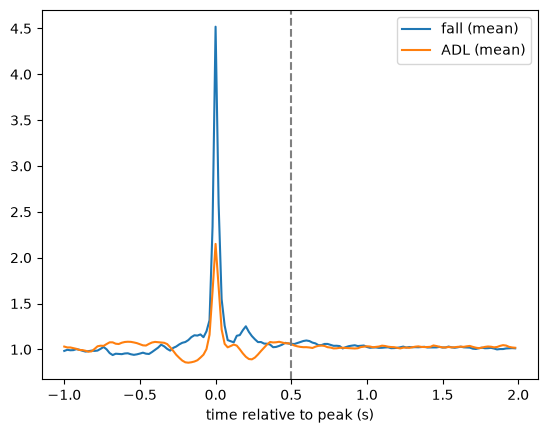

In [12]:
t = (np.arange(x.shape[1]) / 50) - 1
plt.plot(t, x[y == 1].mean(axis=0), label="fall (mean)")
plt.plot(t, x[y == 0].mean(axis=0), label="ADL (mean)")
plt.axvline(0.5, linestyle="--", color="gray")
plt.xlabel("time relative to peak (s)"); plt.legend(); plt.show()

Markdown
## 8. Feature Extraction and Statistical Summarization

To train the I converted the raw time-series into a structured set of summary features. 

For this purpose, I created the `feature_selection` function. It splits each 3-second window into three temporal segments:
1. **`all`**: The entire 3-second window.
2. **`pre`**: The period leading up to the impact (`x[:, :fs]`).
3. **`post`**: The recovery period starting $0.5$ seconds after the impact peak (`x[:, fs + 25:]`, as was check previously).

Across each of these segments, it computes four fundamental statistical metrics (`max`, `min`, `mean`, `std`), resulting in a clean feature matrix and a list of corresponding feature names.

In [13]:
feature_matrix, feature_names = feature_selection(x, fs)

## 9. Model Selection & Configuration

To find the best balance between accuracy, interpretability, and hardware constraints, I defined a dictionary of candidate models. 

Since our goal is to eventually deploy this model onto an **Arduino**, we want to test both standard baselines and heavily constrained models:
* **`logreg` (Logistic Regression):** A simple linear model paired with a `StandardScaler` to normalize features. It acts as a fast, lightweight baseline.
* **`rf` (Random Forest):** A robust ensemble model with 200 trees. While it usually yields high accuracy, it can be too memory-heavy for a microcontroller.
* **`rf_small` (Constrained Random Forest):** A trimmed-down version of the Random Forest with only 10 estimators and a `max_depth` of 5, designed to test if we can get ensemble benefits under strict memory limits.
* **`tree` (Decision Tree):** A shallow decision tree (`max_depth=4`). This is an ideal candidate for Arduino deployment because it can be easily converted into clean, ultra-fast C/C++ code (e.g., using `emlearn`).

Additionally, all models use **`class_weight="balanced"`** to automatically handle the class imbalance between our ADL and Fall samples.

In [14]:
models = {
    "logreg": make_pipeline(StandardScaler(),
                            LogisticRegression(class_weight="balanced", max_iter=1000)),
    "rf": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "rf_small": RandomForestClassifier(n_estimators=10, max_depth=5, class_weight="balanced", random_state=42),
    "tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
}

## 10. Subject-Aware Data Splitting & Cross-Validation Strategy

To ensure our model generalizes well to **completely unseen people** (which is essential for a real-world wearable fall-detection system), we cannot use standard random train-test splits. If data from the same participant appears in both training and testing sets, the model will memorize person-specific walking quirks rather than learning true fall patterns (data leakage).

To prevent this, I use two advanced cross-validation tools:
1. **`GroupShuffleSplit`:** Splits our dataset at the **subject level** (using `groups`), holding out 25% of the participants entirely (`f_hold`, `y_hold`) for final evaluation, while keeping 75% for development (`f_dev`, `y_dev`).
2. **`StratifiedGroupKFold`:** Sets up a 5-fold cross-validation strategy for our development set. It ensures that participant groups never overlap between folds while maintaining a balanced class ratio of falls and ADLs in every fold.

After I perform the group split and verify two things:
* The class balance via `bincount`.
* That there is **zero overlap** of subject IDs between our development and holdout sets (`set(...) & set(...)` should print an empty set `{}`).

In [15]:
splits = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)

work_idx, hold_idx = next(splits.split(feature_matrix, y, groups=groups))

f_dev, y_dev, g_dev = feature_matrix[work_idx], y[work_idx], groups[work_idx]

f_hold, y_hold, g_hold = feature_matrix[hold_idx], y[hold_idx], groups[hold_idx]

fold = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

print(np.bincount(y_dev), np.bincount(y_hold))
print(set(groups[work_idx]) & set(groups[hold_idx])) 

[934 356] [398 110]
set()


## 11. Model Evaluation & Cross-Validation Results

To evaluate how well our models perform, we define a scoring dictionary tracking four critical metrics for fall detection:
* **Sensitivity (Recall):** Measures how many actual falls the model successfully catches (crucial to avoid missing a dangerous fall).
* **Specificity:** Measures how many daily activities are correctly identified as safe (crucial to minimize annoying false alarms).
* **Balanced Accuracy:** The average of sensitivity and specificity, great for handling class imbalance.
* **ROC AUC:** Measures the overall discriminative ability of the model.

Using `cross_validate` with our subject-aware `StratifiedGroupKFold` strategy, we evaluate all four candidate models across our development dataset

In [16]:
scoring = {
  "sensitivity": "recall",
  "specificity": make_scorer(recall_score, pos_label=0),
  "balanced_accuracy": "balanced_accuracy",
  "roc_auc": "roc_auc",

}

results = {}
for name, model in models.items():
    res = cross_validate(model, f_dev, y_dev, groups=g_dev, cv=fold, scoring=scoring)
    results[name] = res
    print(name)
    for metric in scoring:
        s = res[f"test_{metric}"]
        print(f"  {metric}: {s.mean():.2f} ± {s.std():.2f}")

logreg
  sensitivity: 0.88 ± 0.11
  specificity: 0.90 ± 0.05
  balanced_accuracy: 0.89 ± 0.05
  roc_auc: 0.95 ± 0.03
rf
  sensitivity: 0.90 ± 0.06
  specificity: 0.95 ± 0.02
  balanced_accuracy: 0.93 ± 0.03
  roc_auc: 0.98 ± 0.01
rf_small
  sensitivity: 0.90 ± 0.06
  specificity: 0.90 ± 0.02
  balanced_accuracy: 0.90 ± 0.02
  roc_auc: 0.97 ± 0.01
tree
  sensitivity: 0.90 ± 0.06
  specificity: 0.87 ± 0.02
  balanced_accuracy: 0.88 ± 0.02
  roc_auc: 0.91 ± 0.02


## 11. Model Selection, Feature Importance & Threshold Optimization

With **`rf_small`** showing strong potential as a lightweight model, I delve deeper into optimizing and auditing its performance:
1. **Feature Importance:** Identifying which statistical metrics and temporal segments drive the model's decisions.
2. **Threshold Tuning:** Analyzing how adjusting the classification probability threshold (`thr`) affects sensitivity, specificity, missed falls and false alarms.
3. **Pre-Trigger Design:** Implementing an accelerometer peak threshold (`trigger`) to efficiently filter out non-fall windows before running heavy model inference.
4. **False Alarm Analysis:** Pinpointing exactly which Activities of Daily Living (ADLs) are causing false alarms so we can understand the model's limitations.

In [55]:
rf_small = models["rf_small"].fit(f_dev, y_dev)
n_features = 5

for name, imp in sorted(zip(feature_names, rf_small.feature_importances_), key=lambda p: -p[1]):
    print(f"{name}: {imp:.3f}")

best_features = [name for name, imp in sorted(zip(feature_names, rf_small.feature_importances_), key=lambda p: -p[1])][:n_features]

print("Best features:", best_features)
print("nodes:", sum(t.tree_.node_count for t in rf_small.estimators_))
print(rf_small.get_params()["n_estimators"], rf_small.get_params()["max_depth"])

all_mean: 0.322
all_max: 0.241
pre_std: 0.097
all_min: 0.082
pre_max: 0.068
post_std: 0.051
post_min: 0.050
all_std: 0.026
pre_min: 0.024
post_max: 0.013
post_mean: 0.012
pre_mean: 0.012
Best features: ['all_mean', 'all_max', 'pre_std', 'all_min', 'pre_max']
nodes: 450
10 5


In [89]:
f_best = f_dev[:, [feature_names.index(f) for f in best_features]]

res_small = cross_validate(rf_small, f_best, y_dev, groups=g_dev, cv=fold, scoring=scoring)
results["rf_small_5"] = res_small
print("results for rf_small with the 5 best features:")
for metric in scoring:
    s = res_small[f"test_{metric}"]
    print(f"  {metric}: {s.mean():.2f} ± {s.std():.2f}")


results for rf_small with the 5 best features:
  sensitivity: 0.91 ± 0.07
  specificity: 0.89 ± 0.01
  balanced_accuracy: 0.90 ± 0.04
  roc_auc: 0.96 ± 0.02


In [76]:
m = models["rf_small"]
proba = cross_val_predict(m, f_dev, y_dev, groups=g_dev, cv=fold,
                          method="predict_proba")[:, 1]

for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, pred).ravel()
    print(f"thr={thr}: sens={tp/(tp+fn):.2f}  spec={tn/(tn+fp):.2f}  missed={fn}  false alarms={fp}")

thr=0.3: sens=0.98  spec=0.82  missed=7  false alarms=169
thr=0.4: sens=0.95  spec=0.86  missed=17  false alarms=135
thr=0.5: sens=0.91  spec=0.90  missed=33  false alarms=98
thr=0.6: sens=0.87  spec=0.93  missed=48  false alarms=66
thr=0.7: sens=0.82  spec=0.95  missed=65  false alarms=50


In [91]:
rf_small = models["rf_small"].fit(f_best, y_dev)

m = models["rf_small"]
new_proba = cross_val_predict(m, f_best, y_dev, groups=g_dev, cv=fold,
                          method="predict_proba")[:, 1]

for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    new_pred = (new_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, new_pred).ravel()
    print(f"thr={thr}: sens={tp/(tp+fn):.2f}  spec={tn/(tn+fp):.2f}  missed={fn}  false alarms={fp}")

thr=0.3: sens=0.95  spec=0.81  missed=17  false alarms=180
thr=0.4: sens=0.94  spec=0.85  missed=23  false alarms=139
thr=0.5: sens=0.92  spec=0.89  missed=30  false alarms=106
thr=0.6: sens=0.88  spec=0.92  missed=42  false alarms=77
thr=0.7: sens=0.82  spec=0.94  missed=63  false alarms=55


In [81]:
peaks = f_dev[:, feature_names.index("all_max")]     

fall_peaks = peaks[y_dev == 1]
adl_peaks  = peaks[y_dev == 0]
    

trigger = np.percentile(fall_peaks, 5)   
print("trigger threshold:", round(trigger, 2), "g")
print("falls that would fire it:", (fall_peaks >= trigger).mean())
print("ADL windows that would fire it:", (adl_peaks >= trigger).mean())

passed = adl_peaks >= trigger
passed_falls = fall_peaks >= trigger
adl_proba = proba[y_dev == 0]
fall_proba = proba[y_dev == 1]

print("true alarm rate after trigger:", (fall_proba[passed_falls] >= 0.4).mean())
print("false alarm rate after trigger:", (adl_proba[passed] >= 0.4).mean())


trigger threshold: 2.67 g
falls that would fire it: 0.949438202247191
ADL windows that would fire it: 0.19164882226980728
true alarm rate after trigger: 0.9763313609467456
false alarm rate after trigger: 0.6089385474860335


In [84]:
new_peaks = f_best[:, best_features.index("all_max")]     

new_fall_peaks = new_peaks[y_dev == 1]
new_adl_peaks  = new_peaks[y_dev == 0]
    

new_trigger = np.percentile(new_fall_peaks, 5)   
print("trigger threshold:", round(new_trigger, 2), "g")
print("falls that would fire it:", (new_fall_peaks >= new_trigger).mean())
print("ADL windows that would fire it:", (new_adl_peaks >= new_trigger).mean())

new_passed = new_adl_peaks >= new_trigger
new_passed_falls = new_fall_peaks >= new_trigger
new_adl_proba = new_proba[y_dev == 0]
new_fall_proba = new_proba[y_dev == 1]

print("true alarm rate after trigger:", (new_fall_proba[new_passed_falls] >= 0.4).mean())
print("false alarm rate after trigger:", (new_adl_proba[new_passed] >= 0.4).mean())


trigger threshold: 2.67 g
falls that would fire it: 0.949438202247191
ADL windows that would fire it: 0.19164882226980728
true alarm rate after trigger: 0.9704142011834319
false alarm rate after trigger: 0.5586592178770949


In [85]:
fires = peaks >= trigger
act = x_bp["ActivityID"].values[work_idx]
bad = (y_dev == 0) & fires & (proba >= 0.4)
counts = pd.Series(act[bad]).value_counts()
counts = counts.rename(index=ACTIVITY_NAMES)
print(counts)

Jumping strongly         23
Jumping slightly         22
Stumbling                15
Fail to stand up         12
Downstairs quickly        8
Stop jogging              7
Walking quickly           5
Jogging slowly            3
Lying down                3
Turning while lying       3
Upstairs quickly          2
Start jogging             2
Sitting down              1
Standing up               1
Stop walking              1
Stop going downstairs     1
Name: count, dtype: int64


In [86]:
new_fires = new_peaks >= new_trigger
act = x_bp["ActivityID"].values[work_idx]
bad = (y_dev == 0) & new_fires & (new_proba >= 0.4)
counts = pd.Series(act[bad]).value_counts()
counts = counts.rename(index=ACTIVITY_NAMES)
print(counts)

Stumbling                15
Fail to stand up         13
Jumping strongly         12
Jumping slightly         11
Stop jogging             10
Downstairs quickly        7
Walking quickly           6
Start jogging             6
Jogging quickly           4
Jogging slowly            3
Lying down                3
Turning while lying       3
Sitting down              2
Stop walking              2
Upstairs quickly          1
Standing up               1
Stop going downstairs     1
Name: count, dtype: int64


### Analysis of False Alarms

All numbers below use a model threshold of 0.4, on the working set and cross-validated predictions on the working set.

A 2.67 g peak trigger (the 5th percentile of fall peaks) lets through about 95% of falls and 19.2% of ADL windows. Of the ADL windows that pass, the model flags 60.9% as falls, giving 109 false alarms, about 11.7% of the 934 ADL windows. The trigger removes most ADL windows but only a minority of the false alarms (135 without it), and it misses some falls by design.

**False-alarm windows by activity** (counts, not rates):
* **Jumping (strongly / slightly):** 23 (12 + 11)
* **Stumbling:** 15
* **Fail to stand up:** 13
* **Stairs (downstairs / upstairs quickly, stop going downstairs):** 11 (8 + 2 + 1)
* **Jogging and walking (stop jogging, walking quickly, jogging slowly, start jogging, stop walking):** 18
* **Lying down, turning while lying, sitting down, standing up:** 8

All numbers below use the 5-feature small forest (`all_mean`, `all_max`, `pre_std`, `all_min`, `pre_max`), a model threshold of 0.4, and cross-validated predictions on the working set.

A 2.67 g peak trigger (the 5th percentile of fall peaks) lets through about 95% of falls and 19.2% of ADL windows. Of the 179 ADL windows that pass, the model flags 100 as falls (55.9%), about 10.7% of the 934 ADL windows. Combined, the trigger and model catch 328 of 356 falls (92.1%). Without the trigger the same model catches 333 falls and produces 139 false alarms, so the trigger costs 5 falls and removes 39 false alarms.

**False-alarm windows by activity** (counts, not rates):
* **Jogging and fast walking** (stop jogging 10, start jogging 6, jogging quickly 4, jogging slowly 3, walking quickly 6, stop walking 2): 31
* **Jumping** (strongly 12, slightly 11): 23
* **Stumbling:** 15
* **Fail to stand up:** 13
* **Stairs** (downstairs quickly 7, upstairs quickly 1, stop going downstairs 1): 9
* **Lying down, turning while lying, sitting down, standing up:** 9

Compared with the 12-feature model (109 false alarms), the total is similar but the mix changed: jumping fell from 45 to 23, while jogging and fast walking rose from 18 to 31.

The activities involved are mostly vigorous movements and collapses that produce impact peaks similar to falls. A likely reason is that acceleration magnitude carries no information about direction or posture, so a hard landing and a fall can look alike. This is a hypothesis, not something tested here.

### Future Improvements & Conclusion
A natural next step is to use the three axes instead of only the magnitude, for example the change in gravity direction before and after the impact. Judging by the activity names, most of the false alarms above end upright or seated, whereas a fall usually ends with the person lying down, so a posture feature could help for most of them, but not for lying down or turning while lying. Longer post-impact windows and a confirmation step on the device (e.g. a cancel button) are other options. Using axes makes the model sensitive to how the board is mounted, which has to be handled on the Arduino.

For a first prototype these results are adequate, but they come from simulated falls, windows centered on the largest peak, and cross-validation only. The held-out evaluation and a measurement of false alarms on continuous recordings are still to do.
